# Water boiling point vs. altitude: does the barometric formula match published values?

**Question.** How well does the simple barometric formula predict the boiling point of water at altitude, compared with published measurements?

**Data.** A reference table of 250 rows from two sources, each row labelled by `data_type`:
- *Engineering ToolBox* "Water - Boiling Points vs. Altitude" (125 rows, `computed_unknown_method`: the page does not state its method).
- *IAPWS-IF97* saturation temperatures (125 rows, `computed_reference`), computed at ISA standard-atmosphere pressures for the same altitudes.

The table contains **zero measured rows**. Without measurements, this demo can only check whether the published values are independent of the standard-atmosphere model.

**Model.** No trained model. The notebook groups the rows by source and compares the ToolBox boiling temperature with the IAPWS value at the same altitude.

**What you will see.** The source counts, a table of paired boiling temperatures and their differences in kelvin, and a plot of those differences against altitude.

This notebook runs on a 50-row curated subset (`mini_demo_data.json`: 25 altitudes present in both sources), loaded from GitHub with a local fallback.

In [1]:
# Install dependencies. The script itself uses only the standard library.
# matplotlib is used for the figure; on Colab it is preinstalled and must not be reinstalled.
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Core package: pre-installed on Colab, install locally at Colab's exact version only
if 'google.colab' not in sys.modules:
    _pip('matplotlib==3.10.0')

## Setup: imports and figure style

The original script imports `json` and `Path`. The notebook adds the data-loading imports and the shared figure style.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

## Load the data

The notebook reads `mini_demo_data.json` from GitHub. If the download fails (for example, before the repository is published), it falls back to the local copy in this folder.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-fde7b3-simple-barometric-model-vs-boiling-point/main/round-1/dataset-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"])
print({d["dataset"]: len(d["examples"]) for d in data["datasets"]})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'description': 'Curated demo subset (25 altitudes, paired across both sources, 50 rows) of the water boiling-temperature vs altitude reference table. No measured rows.', 'n_measured': 0, 'n_computed_reference': 25, 'n_computed_unknown_method': 25, 'n_examples': 50, 'full_table_rows': 250}
{'engtoolbox_boiling_altitude': 25, 'iapws_if97_saturation': 25}


## Config

The tunable parameter is how many paired altitudes the comparison uses. The loaded subset has 25 paired altitudes, so the demo uses all 25. Lower it (for example to 5) for a faster smoke test.

In [5]:
# Number of paired altitudes (ToolBox and IAPWS rows at the same altitude) used in the comparison.
N_ALTITUDES = 25  # all 25 paired altitudes in the mini subset (the full table has 125)

## Processing 1: group the rows by source

This section follows the original `main()`, which groups the rows by `source_id` and counts them. The loaded data is already grouped, so the notebook reads each group directly.

In [6]:
# Group examples by source, as the original main() does with source_id.
groups = {d["dataset"]: d["examples"] for d in data["datasets"]}
out_metadata = data["metadata"]
print({name: len(ex) for name, ex in groups.items()})
print("measured rows:", out_metadata["n_measured"],
      "| computed_reference:", out_metadata["n_computed_reference"],
      "| computed_unknown_method:", out_metadata["n_computed_unknown_method"])

{'engtoolbox_boiling_altitude': 25, 'iapws_if97_saturation': 25}
measured rows: 0 | computed_reference: 25 | computed_unknown_method: 25


## Processing 2: compare ToolBox with IAPWS at the same altitude

The ToolBox values are compared with the IAPWS-at-ISA value at each altitude. A difference near zero means the published table agrees with a standard-atmosphere calculation. That would make it a computed benchmark, not independent evidence.

In [7]:
# Index each source by altitude; the output field holds the boiling temperature in kelvin.
tb_by_alt = {e["metadata_altitude_m"]: float(e["output"]) for e in groups["engtoolbox_boiling_altitude"]}
ip_by_alt = {e["metadata_altitude_m"]: float(e["output"]) for e in groups["iapws_if97_saturation"]}

# Keep the first N_ALTITUDES altitudes that appear in both sources.
paired_alts = sorted(set(tb_by_alt) & set(ip_by_alt))[:N_ALTITUDES]
residuals = {a: tb_by_alt[a] - ip_by_alt[a] for a in paired_alts}  # ToolBox minus IAPWS, in K

## Results

The table lists each paired altitude with its ToolBox value, IAPWS value and difference in kelvin. The plot shows the differences against altitude, with a zero line for reference.

altitude_m  ToolBox_K    IAPWS_K   diff_K
      -305     374.25    374.137    +0.11
        76     372.85    372.872    -0.02
       457     371.55    371.605    -0.06
       914     369.95    370.085    -0.13
      1295     368.65    368.816    -0.17
      1676     367.35    367.546    -0.20
      2057     366.05    366.275    -0.22
      2438     364.75    365.002    -0.25
      2819     363.45    363.728    -0.28
      3200     362.25    362.453    -0.20
      3658     360.75    360.917    -0.17
      4037     359.55    359.645    -0.09
      4420     358.25    358.358    -0.11
      4801     357.05    357.075    -0.02
      5182     355.85    355.791    +0.06
      5639     354.45    354.249    +0.20
      6020     353.35    352.960    +0.39
      6401     352.15    351.670    +0.48
      6782     351.05    350.378    +0.67
      7163     349.95    349.083    +0.87
      7544     348.75    347.786    +0.96
      7925     347.65    346.487    +1.16
      8382     346.35    344.926  

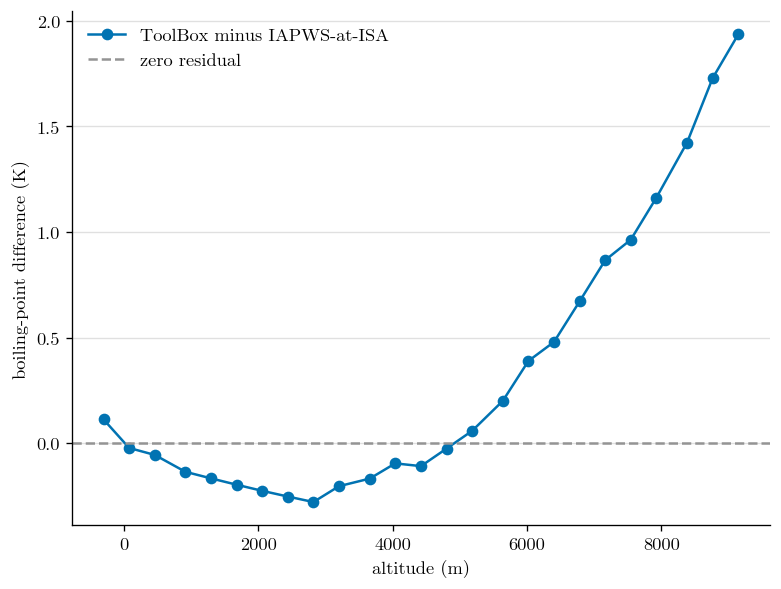

In [8]:
import statistics

print(f"{'altitude_m':>10} {'ToolBox_K':>10} {'IAPWS_K':>10} {'diff_K':>8}")
for a in paired_alts:
    print(f"{a:>10} {tb_by_alt[a]:>10.2f} {ip_by_alt[a]:>10.3f} {residuals[a]:>+8.2f}")

vals = list(residuals.values())
print(f"\nmin {min(vals):+.2f} K, max {max(vals):+.2f} K, median {statistics.median(vals):+.2f} K over {len(vals)} altitudes")

fig, ax = plt.subplots()
ax.plot(paired_alts, [residuals[a] for a in paired_alts], marker="o",
        color=COLOURS["method"], label="ToolBox minus IAPWS-at-ISA")
ax.axhline(0, color=COLOURS["baseline"], linestyle="--", label="zero residual")
ax.set_xlabel("altitude (m)")
ax.set_ylabel("boiling-point difference (K)")
ax.legend()
plt.show()

## Interpreting the results

The printed table and plot show how far each ToolBox boiling temperature sits from the IAPWS value computed at the standard-atmosphere pressure for the same altitude. Differences of a few tenths of a kelvin, centred near zero, mean the published table matches a standard-atmosphere calculation. This is consistent with the ToolBox values being computed rather than measured.

For the claim this artifact tests, the consequence is this: the table has no measured rows, so it cannot show how well the barometric formula predicts real boiling points. Matching IAPWS-at-ISA shows only that the benchmark is not independent of the model. The full 125-altitude comparison in the source artifact gives a range of -0.31 to +1.94 K with a median of +0.02 K. This demo prints the subset values above.